In [2]:

import pymc as pm
import pytensor.tensor as pt
import numpy as np
import arviz as az

from models.melodic_markov_model import MelodicMarkovModel
from models.mm_mode_independent_model import MarkovModeIndependentModel
from models.mm_mode_region_independent import MarkovModeRegionIndependent
from data.GradualePipeline import GradualePipeline


In [3]:
data = GradualePipeline.load("data/processed/dataset_pitches_modes.pkl")
data

{'x_0_obs': array([ 6,  7,  7,  2,  6,  3,  7,  5,  6,  3,  5,  5,  5,  3,  5,  3,  3,
         4,  6,  3,  3,  6,  5,  6,  7,  5,  4,  2,  6,  5,  5,  3,  3,  6,
         9,  5,  5,  7,  6,  7,  3,  3,  6,  6,  5,  9,  3,  7,  9,  3,  3,
         5,  3,  6,  8,  6,  8,  6, 10,  6,  5,  3,  9,  6,  9,  8,  6,  5,
         3,  4,  3,  9,  9,  3,  7,  2,  9,  3,  3,  2,  6,  2,  3,  2,  3,
         6,  3,  3,  3,  7,  6,  5,  6,  5,  3,  7,  5,  7,  6,  6,  5,  9,
         6,  3,  5,  3,  7,  5,  7,  7,  3,  4,  5,  9,  9,  3,  3,  4,  9,
         6,  3,  7,  5,  6,  3,  5,  7,  5,  7,  9,  3,  6,  3,  3]),
 'x_t_obs': array([[ 6,  7,  6, ...,  6,  5,  5],
        [ 7,  7,  5, ...,  5,  5,  3],
        [ 8,  6,  6, ...,  5,  6,  3],
        ...,
        [-1, -1, -1, ..., -1, -1, -1],
        [-1, -1, -1, ..., -1, -1, -1],
        [-1, -1, -1, ..., -1, -1, -1]], shape=(428, 134)),
 'lengths_obs': array([385, 201, 104,  80, 222, 211, 140, 158, 219, 279, 260,  98, 145,
        103, 109, 154

In [4]:
data_r = GradualePipeline.load("data/processed/dataset_pitches_modes_regions.pkl")
data_r

{'x_0_obs': array([ 6,  7,  7,  2,  6,  3,  7,  5,  6,  3,  5,  5,  5,  3,  5,  3,  3,
         4,  6,  3,  3,  6,  5,  6,  7,  5,  4,  2,  6,  5,  5,  3,  3,  6,
         9,  5,  5,  7,  6,  7,  3,  3,  6,  6,  5,  9,  3,  7,  9,  3,  3,
         5,  3,  6,  8,  6,  8,  6, 10,  6,  5,  3,  9,  6,  9,  8,  6,  5,
         3,  4,  3,  9,  9,  3,  7,  2,  9,  3,  3,  2,  6,  2,  3,  2,  3,
         6,  3,  3,  3,  7,  6,  5,  6,  5,  3,  7,  5,  7,  6,  6,  5,  9,
         6,  3,  5,  3,  7,  5,  7,  7,  3,  4,  5,  9,  9,  3,  3,  4,  9,
         6,  3,  7,  5,  6,  3,  5,  7,  5,  7,  9,  3,  6,  3,  3]),
 'x_t_obs': array([[ 6,  7,  6, ...,  6,  5,  5],
        [ 7,  7,  5, ...,  5,  5,  3],
        [ 8,  6,  6, ...,  5,  6,  3],
        ...,
        [-1, -1, -1, ..., -1, -1, -1],
        [-1, -1, -1, ..., -1, -1, -1],
        [-1, -1, -1, ..., -1, -1, -1]], shape=(428, 134)),
 'lengths_obs': array([385, 201, 104,  80, 222, 211, 140, 158, 219, 279, 260,  98, 145,
        103, 109, 154

## Simple Markov Model vs. Markov Independent Mode Model
Building a model comparison with a Hierarchical Dirichlet approach

In [4]:

def prepare_sequence_data(initial_states_obs, sequence_states_obs, sequence_lengths_obs):
    initial_states_padded = pt.shape_padleft(initial_states_obs)
    all_states = pt.concatenate([initial_states_padded, sequence_states_obs], axis=0)
    
    prev_states = all_states[:-1]
    current_states = all_states[1:]

    time_indices = pt.arange(sequence_states_obs.shape[0])
    valid_time_mask = time_indices[:, None] < sequence_lengths_obs[None, :]
    
    valid_prev_states = prev_states[valid_time_mask]
    valid_current_states = current_states[valid_time_mask]
    
    return prev_states, current_states, valid_prev_states, valid_current_states, valid_time_mask


def build_mixture_supermodel(initial_states_obs, sequence_states_obs, sequence_lengths_obs, mode_obs):
    m_base = MelodicMarkovModel()
    m_mode = MarkovModeIndependentModel()
    
    with pm.Model() as supermodel:
        # Approach suggested at: https://discourse.pymc.io/t/how-to-do-model-comparison-with-a-dummy-variable/12903/7
        w = pm.Dirichlet("model_weights", a=np.ones(2))
        
        with pm.Model(name="base"):
            base_init_probs, base_transition = m_base._define_priors()
            
        with pm.Model(name="mode"):
            mode_probs, mode_transition, mode_init_probs = m_mode._define_priors()
            
        prev, curr, valid_prev, valid_curr, valid_mask = prepare_sequence_data(
            initial_states_obs, sequence_states_obs, sequence_lengths_obs
        )
        
        init_logp_base = pm.logp(pm.Categorical.dist(p=base_init_probs), initial_states_obs)
        step_logp_base = pm.logp(pm.Categorical.dist(p=base_transition[valid_prev]), valid_curr)
        ll_base = pt.sum(init_logp_base) + pt.sum(step_logp_base)
        
        init_logp_mode = pm.logp(pm.Categorical.dist(p=mode_init_probs), initial_states_obs)
        seq_ll_mode = m_mode._calculate_sequence_logp(prev, curr, valid_mask, mode_transition, mode_obs)
        ll_mode = pt.sum(init_logp_mode) + seq_ll_mode
        
        logp_mixture = pm.math.logsumexp(pt.log(w) + pt.stack([ll_base, ll_mode]))
        pm.Potential("mixture_likelihood", logp_mixture)
    return supermodel


In [5]:

supermodel = build_mixture_supermodel(
    initial_states_obs=data["x_0_obs"], 
    sequence_states_obs=data["x_t_obs"], 
    sequence_lengths_obs=data["lengths_obs"], 
    mode_obs=data["m_obs"]
)


In [6]:

with supermodel:
    trace = pm.sample(draws=3000, tune=1000, chains=4, target_accept=0.9)
trace.to_netcdf("samples/trace_comparison_smm_mode_indep.nc")

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [model_weights, base::init_probs, base::transition_matrix, mode::mode_probs, mode::mode_transition_matrices, mode::init_probs]


Output()

Sampling 4 chains for 1_000 tune and 3_000 draw iterations (4_000 + 12_000 draws total) took 2504 seconds.
The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details
The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


'samples/trace_comparison_smm_mode_indep.nc'

array([[<Axes: title={'center': 'model_weights'}>,
        <Axes: title={'center': 'model_weights'}>]], dtype=object)

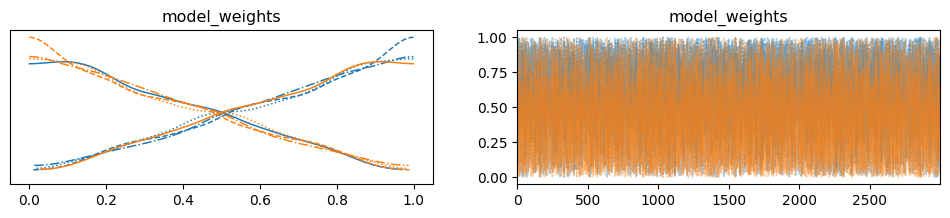

In [7]:
az.plot_trace(trace, var_names=["model_weights"])

In [8]:

weights = trace.posterior["model_weights"].values

w_base_mean = weights[..., 0].mean()
w_mode_mean = weights[..., 1].mean()

print(f"Posterior prob Base Model: {w_base_mean:.4f}")
print(f"posterior prob Mode Model: {w_mode_mean:.4f}")

if w_base_mean > 0:
    bf_10 = w_mode_mean / w_base_mean
    print(f"\nBayes Factor: {bf_10:.4f}")
else:
    print("\nBayes Factor: unendlich")

Posterior prob Base Model: 0.5840
posterior prob Mode Model: 0.4160

Bayes Factor: 0.7124


## Simple Markov Model vs. Markov Independent Mode & Region Model


In [5]:
def build_region_supermodel(initial_states_obs, sequence_states_obs, sequence_lengths_obs, mode_obs, region_obs):
    m_base = MelodicMarkovModel()
    m_region = MarkovModeRegionIndependent()
    
    with pm.Model() as supermodel:
        w = pm.Dirichlet("model_weights", a=np.ones(2))
        
        with pm.Model(name="base"):
            base_init_probs, base_transition = m_base._define_priors()
            
        with pm.Model(name="region"):
            mode_probs, region_mode_transition_matrices, region_init_probs = m_region._define_priors()
            
        prev, curr, valid_prev, valid_curr, valid_mask = prepare_sequence_data(
            initial_states_obs, sequence_states_obs, sequence_lengths_obs
        )
        
        init_logp_base = pm.logp(pm.Categorical.dist(p=base_init_probs), initial_states_obs)
        step_logp_base = pm.logp(pm.Categorical.dist(p=base_transition[valid_prev]), valid_curr)
        ll_base = pt.sum(init_logp_base) + pt.sum(step_logp_base)
        
        init_logp_region = pm.logp(pm.Categorical.dist(p=region_init_probs), initial_states_obs)
        seq_ll_region = m_region._calculate_sequence_logp(
            prev, 
            curr, 
            valid_mask, 
            region_mode_transition_matrices, 
            mode_obs, 
            region_obs
        )
        ll_region = pt.sum(init_logp_region) + seq_ll_region
        
        logp_mixture = pm.math.logsumexp(pt.log(w) + pt.stack([ll_base, ll_region]))
        pm.Potential("mixture_likelihood", logp_mixture)
        
    return supermodel

In [6]:
region_supermodel = build_region_supermodel(
    initial_states_obs=data_r["x_0_obs"], 
    sequence_states_obs=data_r["x_t_obs"], 
    sequence_lengths_obs=data_r["lengths_obs"], 
    mode_obs=data_r["m_obs"],
    region_obs=data_r["region_obs"]
)

In [7]:

with region_supermodel:
    trace_region = pm.sample(draws=4000, tune=1000, chains=4, target_accept=0.9)

trace_region.to_netcdf("samples/trace_comparison_smm_regio_indep_two.nc")

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [model_weights, base::init_probs, base::transition_matrix, region::global_mode_probs, region::kappa, region::mode_probs, region::region_mode_transition_matrices, region::init_probs]


Output()

Sampling 4 chains for 1_000 tune and 4_000 draw iterations (4_000 + 16_000 draws total) took 19630 seconds.
There were 689 divergences after tuning. Increase `target_accept` or reparameterize.
The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details
The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


'samples/trace_comparison_smm_regio_indep_two.nc'

array([[<Axes: title={'center': 'model_weights'}>,
        <Axes: title={'center': 'model_weights'}>]], dtype=object)

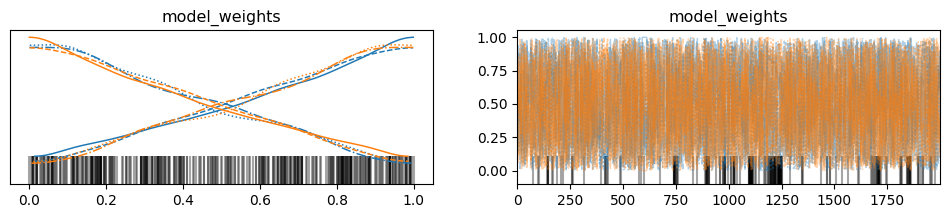

In [8]:
az.plot_trace(trace_region, var_names=["model_weights"])

In [9]:

weights = trace_region.posterior["model_weights"].values

w_base_mean = weights[..., 0].mean()
w_mode_mean = weights[..., 1].mean()

print(f"Posterior prob Base Model: {w_base_mean:.4f}")
print(f"posterior prob Mode Model: {w_mode_mean:.4f}")

if w_base_mean > 0:
    bf_10 = w_mode_mean / w_base_mean
    print(f"\nBayes Factor: {bf_10:.4f}")
else:
    print("\nBayes Factor: unendlich")

Posterior prob Base Model: 0.4967
posterior prob Mode Model: 0.5033

Bayes Factor: 1.0132


## Simple Markov Model vs. Simple Melodic Rules Model



In [1]:

import pymc as pm
import pytensor.tensor as pt
import numpy as np
import arviz as az

from models.melodic_markov_model import MelodicMarkovModel
from models.mm_musical_components2 import MelodicComponentsIIMarkovModel


def prepare_sequence_data(initial_states_obs, sequence_states_obs, sequence_lengths_obs):
    initial_states_padded = pt.shape_padleft(initial_states_obs)
    all_states = pt.concatenate([initial_states_padded, sequence_states_obs], axis=0)
    
    prev_states = all_states[:-1]
    current_states = all_states[1:]

    time_indices = pt.arange(sequence_states_obs.shape[0])
    valid_time_mask = time_indices[:, None] < sequence_lengths_obs[None, :]
    
    valid_prev_states = prev_states[valid_time_mask]
    valid_current_states = current_states[valid_time_mask]
    
    return prev_states, current_states, valid_prev_states, valid_current_states, valid_time_mask


def build_components_vs_markov_supermodel(initial_states_obs, sequence_states_obs, sequence_lengths_obs):
    m_markov = MelodicMarkovModel()
    m_components = MelodicComponentsIIMarkovModel()
    
    with pm.Model() as supermodel:
        # Der kontinuierliche Dimmer (50/50 Prior für beide Modelle)
        w = pm.Dirichlet("model_weights", a=np.ones(2))

        # 1. Priors laden (mit Namespaces gegen Variablen-Kollisionen)
        with pm.Model(name="markov"):
            markov_init_probs, markov_transition = m_markov._define_priors()

        with pm.Model(name="components"):
            comp_init_probs, comp_transition = m_components._define_priors()

        # 2. Daten maskieren
        prev, curr, valid_prev, valid_curr, valid_mask = prepare_sequence_data(
            initial_states_obs, sequence_states_obs, sequence_lengths_obs
        )

        # 3. Log-Likelihood für Modell 0 (Das freie Markov Modell)
        init_logp_markov = pm.logp(pm.Categorical.dist(p=markov_init_probs), initial_states_obs)
        step_logp_markov = pm.logp(pm.Categorical.dist(p=markov_transition[valid_prev]), valid_curr)
        ll_markov = pt.sum(init_logp_markov) + pt.sum(step_logp_markov)

        # 4. Log-Likelihood für Modell 1 (Das strukturierte Components Modell)
        init_logp_comp = pm.logp(pm.Categorical.dist(p=comp_init_probs), initial_states_obs)
        step_logp_comp = pm.logp(pm.Categorical.dist(p=comp_transition[valid_prev]), valid_curr)
        ll_comp = pt.sum(init_logp_comp) + pt.sum(step_logp_comp)

        # 5. DIE MISCHUNG (LogSumExp)
        logp_mixture = pm.math.logsumexp(pt.log(w) + pt.stack([ll_markov, ll_comp]))
        pm.Potential("mixture_likelihood", logp_mixture)
        
    return supermodel


/Users/timeipert/PycharmProjects/generative_medieval_music_model/venvnew/lib/python3.11/site-packages/arviz/__init__.py:50: FutureWarning: 
ArviZ is undergoing a major refactor to improve flexibility and extensibility while maintaining a user-friendly interface.
Some upcoming changes may be backward incompatible.
For details and migration guidance, visit: https://python.arviz.org/en/latest/user_guide/migration_guide.html
  warn(


In [5]:


supermodel3 = build_components_vs_markov_supermodel(
    initial_states_obs=data["x_0_obs"], 
    sequence_states_obs=data["x_t_obs"], 
    sequence_lengths_obs=data["lengths_obs"]
)

with supermodel3:
    # Sampling des Mixture-Modells
    trace3 = pm.sample(draws=4000, tune=1500, chains=4, target_accept=0.9)


# --- ZELLE 5: AUSWERTUNG DES BAYES FACTORS ---
weights = trace3.posterior["model_weights"].values

w_markov_mean = weights[..., 0].mean()
w_comp_mean = weights[..., 1].mean()

print(f"Posteriori-Wahrscheinlichkeit Freies Markov Model: {w_markov_mean:.4f}")
print(f"Posteriori-Wahrscheinlichkeit Components Model:    {w_comp_mean:.4f}")

if w_markov_mean > 0:
    bf_10 = w_comp_mean / w_markov_mean
    print(f"\nBayes Factor (BF_10) für Components vs. Freies Markov: {bf_10:.4f}")
    
    if bf_10 > 30:
        print("-> Sehr starke Evidenz für das strukturierte Components Model.")
    elif bf_10 > 3:
        print("-> Moderate bis starke Evidenz für das Components Model.")
    elif bf_10 < 1:
        print("-> Evidenz spricht für das freie Markov Model (die Regeln greifen zu kurz).")
else:
    print("\nBayes Factor (BF_10): Unendlich (Components Model erklärt die Daten perfekt im Vergleich)")

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [model_weights, markov::init_probs, markov::transition_matrix, components::init_probs, components::weight_interval, components::register_center, components::weight_register, components::weight_repeat, components::weight_direction]


Output()

Sampling 4 chains for 1_500 tune and 4_000 draw iterations (6_000 + 16_000 draws total) took 3867 seconds.


Posteriori-Wahrscheinlichkeit Freies Markov Model: 0.6650
Posteriori-Wahrscheinlichkeit Components Model:    0.3350

Bayes Factor (BF_10) für Components vs. Freies Markov: 0.5038
-> Evidenz spricht für das freie Markov Model (die Regeln greifen zu kurz).


In [6]:

trace3.to_netcdf("samples/trace_comparison_simple_markov_vs_melodic_componet.nc")

'samples/trace_comparison_simple_markov_vs_melodic_componet.nc'

# Melodic Components vs. Melodic Component + Mode + Regio

In [5]:
# --- ZELLE 1: IMPORTS ---
import pymc as pm
import pytensor.tensor as pt
import numpy as np
import arviz as az

# Importiere deine lokalen Modelle
from models.mm_musical_components2 import MelodicComponentsIIMarkovModel
from models.mm_music_components_region_mode import MelodicComponentsRegionModeModel


# --- ZELLE 2: DATEN VORBEREITUNG ---
def prepare_sequence_data(initial_states_obs, sequence_states_obs, sequence_lengths_obs):
    initial_states_padded = pt.shape_padleft(initial_states_obs)
    all_states = pt.concatenate([initial_states_padded, sequence_states_obs], axis=0)
    
    prev_states = all_states[:-1]
    current_states = all_states[1:]

    time_indices = pt.arange(sequence_states_obs.shape[0])
    valid_time_mask = time_indices[:, None] < sequence_lengths_obs[None, :]
    
    valid_prev_states = prev_states[valid_time_mask]
    valid_current_states = current_states[valid_time_mask]
    
    return prev_states, current_states, valid_prev_states, valid_current_states, valid_time_mask


# --- ZELLE 3: DAS MIXTURE SUPERMODELL ---
def build_mixture_supermodel(initial_states_obs, sequence_states_obs, sequence_lengths_obs, mode_obs, region_obs):
    m_base = MelodicComponentsIIMarkovModel()
    m_complex = MelodicComponentsRegionModeModel()
    
    with pm.Model() as supermodel:
        # Der kontinuierliche Dimmer (50/50 Prior)
        w = pm.Dirichlet("model_weights", a=np.ones(2))

        # 1. Priors laden (mit Namespaces gegen Variablen-Kollisionen)
        with pm.Model(name="base"):
            base_init_probs, base_transition = m_base._define_priors()

        with pm.Model(name="complex"):
            # Wir fordern die Dimensionen für Region und Mode an
            complex_init_probs, complex_transition, _ = m_complex._define_priors(use_modes=True, use_regions=True)

        # 2. Daten maskieren
        prev, curr, valid_prev, valid_curr, valid_mask = prepare_sequence_data(
            initial_states_obs, sequence_states_obs, sequence_lengths_obs
        )

        # 3. Log-Likelihood für Modell 0 (Base Model)
        init_logp_base = pm.logp(pm.Categorical.dist(p=base_init_probs), initial_states_obs)
        step_logp_base = pm.logp(pm.Categorical.dist(p=base_transition[valid_prev]), valid_curr)
        ll_base = pt.sum(init_logp_base) + pt.sum(step_logp_base)

        # 4. Log-Likelihood für Modell 1 (Complex Region/Mode Model)
        init_logp_complex = pm.logp(pm.Categorical.dist(p=complex_init_probs), initial_states_obs)
        
        # Um in der 4D-Übergangsmatrix (Region, Mode, Von, Zu) zu navigieren, 
        # brauchen wir die Sequenz-Indizes, genau wie in deiner Klasse definiert.
        sequence_indices = pt.arange(sequence_states_obs.shape[1])[None, :]
        broadcasted_sequence_indices = pt.alloc(sequence_indices, prev.shape[0], prev.shape[1])
        valid_sequence_indices = broadcasted_sequence_indices[valid_mask]

        region_obs_pt = pt.as_tensor_variable(region_obs)
        mode_obs_pt = pt.as_tensor_variable(mode_obs)

        # Die exakten Übergangswahrscheinlichkeiten für den gegebenen Modus/Region herausgreifen
        valid_transition_probs_complex = complex_transition[
            region_obs_pt[valid_sequence_indices], 
            mode_obs_pt[valid_sequence_indices], 
            valid_prev
        ]
        
        step_logp_complex = pm.logp(pm.Categorical.dist(p=valid_transition_probs_complex), valid_curr)
        
        # WICHTIG: Wir addieren hier NICHT die Wahrscheinlichkeit für mode_obs oder region_obs!
        # So bewerten wir rein die Vorhersagekraft für die Melodie.
        ll_complex = pt.sum(init_logp_complex) + pt.sum(step_logp_complex)

        # 5. DIE MISCHUNG (LogSumExp)
        logp_mixture = pm.math.logsumexp(pt.log(w) + pt.stack([ll_base, ll_complex]))
        pm.Potential("mixture_likelihood", logp_mixture)
        
    return supermodel


In [ ]:


# --- ZELLE 4: SAMPLING ---
supermodel4 = build_mixture_supermodel(
    initial_states_obs=data_r["x_0_obs"], 
    sequence_states_obs=data_r["x_t_obs"], 
    sequence_lengths_obs=data_r["lengths_obs"], 
    mode_obs=data_r["m_obs"],
    region_obs=data_r["region_obs"] # Vergiss nicht, die Region-Daten hier zu übergeben!
)

with supermodel4:
    # Mit der sanften Mischung sollte der Sampler nun gut mischen
    trace4 = pm.sample(draws=4000, tune=1500, chains=4, target_accept=0.9)

trace4.to_netcdf("samples/trace_comparison_mus_compo_to_mus_compo_region.nc")

# --- ZELLE 5: AUSWERTUNG DES BAYES FACTORS ---
weights4 = trace4.posterior["model_weights"].values

w_base_mean4 = weights4[..., 0].mean()
w_complex_mean4 = weights4[..., 1].mean()

print(f"Posteriori-Wahrscheinlichkeit Base Model:   {w_base_mean4:.4f}")
print(f"Posteriori-Wahrscheinlichkeit Region/Mode Model: {w_complex_mean4:.4f}")

if w_base_mean4 > 0:
    bf_10 = w_complex_mean4 / w_base_mean4
    print(f"\nBayes Factor (BF_10): {bf_10:.4f}")
    if bf_10 > 30:
        print("-> Sehr starke Evidenz für das Region/Mode Model.")
    elif bf_10 > 3:
        print("-> Moderate bis starke Evidenz für das Region/Mode Model.")
    elif bf_10 < 1:
        print("-> Evidenz spricht für das Base Model.")
else:
    print("\nBayes Factor (BF_10): Unendlich (Region/Mode Model erklärt die Daten perfekt im Vergleich)")

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [model_weights, base::init_probs, base::weight_interval, base::register_center, base::weight_register, base::weight_repeat, base::weight_direction, complex::weight_interval, complex::weight_register, complex::weight_repeat, complex::weight_direction, complex::register_center, complex::init_probs, complex::global_mode_probs, complex::mode_probs_kappa, complex::mode_probs]


Output()